***
The standard NLP pipeline

A typical classical NLP classification system follows this sequence:

1 Raw text

Customer review or email

2 Preprocessing

Normalize text when appropriate

3 Vectorization

Convert text to numbers

4 Model training

Learn patterns from labeled examples

5 Evaluation

Measure generalization on unseen data

6 Deployment

Predict on new incoming text

#### What happens at each stage?
1. Raw text: collect reviews, emails, documents, or messages.
2. Preprocessing: apply task-appropriate cleaning, normalization, and tokenization.
3. Vectorization: convert text into numerical features. A classical model cannot directly learn from an ordinary string.
4. Training: use examples and their labels to estimate model parameters.
5. Evaluation: measure performance on data that was not used to fit the model.
6. Deployment: package the fitted preprocessing and model together so incoming text is processed consistently.

| Requirement | Good starting point |
| :--- | :--- |
| Small labeled dataset, simple classification | TF-IDF + logistic regression |
| Fast spam filtering | Word/character n-grams + linear classifier |
| Entity extraction | spaCy or a pretrained NER model |
| Meaning-based search | Sentence embeddings + retrieval |
| Summarization or natural-language generation | A suitable pretrained language model |
| Questions answered from private documents | RAG with access controls and grounded answers |

### Code
We'll build a complete customer-review sentiment classifier using scikit-learn.

The model will use:
- A small, self-contained labeled dataset.
- TF-IDF vectorization.
- Logistic regression.
- A stratified train/test split.
- Classification metrics and visualizations.
- Model persistence with joblib.
- A reusable prediction function suitable for deployment.

In [1]:
%pip install numpy pandas scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


### Complete end-to-end implementation
Save the following as nlp_overview.py or run it in a notebook.

Dataset shape: (60, 2)

Class distribution:
label
0    30
1    30
Name: count, dtype: int64

Training complete.
Vocabulary size: 225

Test metrics:
Accuracy: 0.333
Precision: 0.364
Recall: 0.571
F1: 0.444

Classification report:
              precision    recall  f1-score   support

    Negative       0.25      0.12      0.17         8
    Positive       0.36      0.57      0.44         7

    accuracy                           0.33        15
   macro avg       0.31      0.35      0.31        15
weighted avg       0.30      0.33      0.30        15



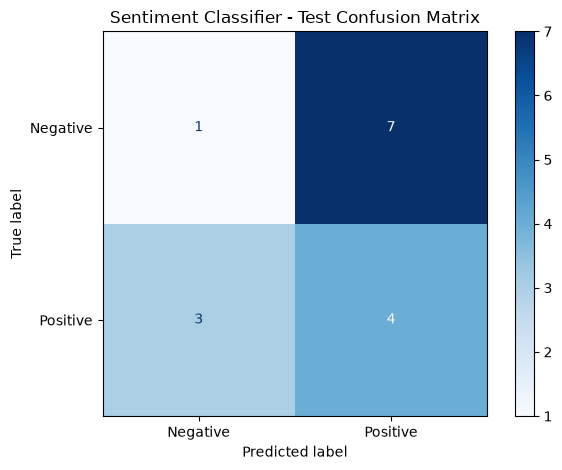


Features most associated with positive sentiment:
excellent                 +0.462
great                     +0.338
good                      +0.281
and great                 +0.256
easy                      +0.247
and easy                  +0.247
fast                      +0.237
delivery                  +0.237
love                      +0.225
love this                 +0.225

Features most associated with negative sentiment:
poor                      -0.416
terrible                  -0.332
disappointed with         -0.322
disappointed              -0.322
never                     -0.315
bad                       -0.291
unreliable                -0.282
and unreliable            -0.282
hate                      -0.254
hate this                 -0.254

New predictions:
{'text': 'The product is excellent and works perfectly', 'sentiment': 'Positive', 'positive_probability': 0.5688}
{'text': 'Terrible quality and very disappointing', 'sentiment': 'Negative', 'positive_probability': 0.491

In [2]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# --------------------------------------------------
# 1. Create a small illustrative dataset
# Label: 1 = positive, 0 = negative
# --------------------------------------------------

positive_reviews = [
    "I love this product",
    "The quality is excellent",
    "Amazing experience and great service",
    "This product works perfectly",
    "Very happy with my purchase",
    "Excellent value for money",
    "The delivery was fast and easy",
    "Fantastic quality and performance",
    "I would definitely recommend it",
    "The product is wonderful",
    "Great experience from start to finish",
    "The service was helpful and friendly",
    "Really good product and reliable performance",
    "I am satisfied with the purchase",
    "Everything worked exactly as expected",
    "Brilliant product and excellent support",
    "The quality exceeded my expectations",
    "Very useful and easy to operate",
    "A great purchase overall",
    "I enjoyed using this product",
    "Fast delivery and great packaging",
    "This is one of my favorite products",
    "Works well and feels premium",
    "Excellent support from the company",
    "I am impressed with the quality",
    "The experience was smooth and pleasant",
    "Affordable and surprisingly good",
    "Very convenient and dependable",
    "I would buy this again",
    "The product is worth the price",
]

negative_reviews = [
    "I hate this product",
    "The quality is terrible",
    "Awful experience and poor service",
    "This product never works properly",
    "Very disappointed with my purchase",
    "Poor value for money",
    "The delivery was late and difficult",
    "Terrible quality and performance",
    "I would never recommend it",
    "The product is horrible",
    "A frustrating experience from start to finish",
    "The service was rude and unhelpful",
    "Really bad product and unreliable performance",
    "I am unhappy with the purchase",
    "Nothing worked as expected",
    "Poor product and terrible support",
    "The quality was below my expectations",
    "Very confusing and difficult to operate",
    "A bad purchase overall",
    "I regret using this product",
    "Late delivery and damaged packaging",
    "This is one of my least favorite products",
    "Works poorly and feels cheap",
    "No useful support from the company",
    "I am disappointed with the quality",
    "The experience was stressful and unpleasant",
    "Overpriced and surprisingly bad",
    "Very inconvenient and unreliable",
    "I would not buy this again",
    "The product is not worth the price",
]

texts = positive_reviews + negative_reviews
labels = np.array([1] * len(positive_reviews) +
                  [0] * len(negative_reviews))

df = pd.DataFrame({
    "text": texts,
    "label": labels,
})

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

# --------------------------------------------------
# 2. Split BEFORE fitting the vectorizer
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.25,
    random_state=42,
    stratify=df["label"],
)

# --------------------------------------------------
# 3. Build the pipeline
# TF-IDF learns vocabulary/IDF from training data only.
# --------------------------------------------------

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=1,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            C=1.0,
            random_state=42,
        ),
    ),
])

# --------------------------------------------------
# 4. Train
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nTraining complete.")
print("Vocabulary size:",
      len(model.named_steps["tfidf"].vocabulary_))

# --------------------------------------------------
# 5. Evaluate on held-out test data
# --------------------------------------------------

y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, y_pred, zero_division=0
    ),
}

print("\nTest metrics:")
for name, value in metrics.items():
    print(f"{name}: {value:.3f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0,
))

# --------------------------------------------------
# 6. Visualize the confusion matrix
# --------------------------------------------------

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Sentiment Classifier - Test Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# --------------------------------------------------
# 7. Inspect important learned features
# --------------------------------------------------

vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
weights = classifier.coef_[0]

top_positive = np.argsort(weights)[-10:][::-1]
top_negative = np.argsort(weights)[:10]

print("\nFeatures most associated with positive sentiment:")
for i in top_positive:
    print(f"{feature_names[i]:25s} {weights[i]:+.3f}")

print("\nFeatures most associated with negative sentiment:")
for i in top_negative:
    print(f"{feature_names[i]:25s} {weights[i]:+.3f}")

# --------------------------------------------------
# 8. Predict on new text
# --------------------------------------------------

def predict_sentiment(text):
    probability = model.predict_proba([text])[0]
    classes = model.named_steps["classifier"].classes_
    positive_index = list(classes).index(1)

    p_positive = float(probability[positive_index])
    sentiment = (
        "Positive" if p_positive >= 0.5 else "Negative"
    )

    return {
        "text": text,
        "sentiment": sentiment,
        "positive_probability": round(p_positive, 4),
    }

examples = [
    "The product is excellent and works perfectly",
    "Terrible quality and very disappointing",
    "The package arrived yesterday",
]

print("\nNew predictions:")
for example in examples:
    print(predict_sentiment(example))

# --------------------------------------------------
# 9. Save the COMPLETE pipeline
# --------------------------------------------------

os.makedirs("artifacts", exist_ok=True)

joblib.dump(model, "artifacts/sentiment_pipeline.joblib")

print("\nSaved model to artifacts/sentiment_pipeline.joblib")

# --------------------------------------------------
# 10. Load it as a deployment smoke test
# --------------------------------------------------

loaded_model = joblib.load(
    "artifacts/sentiment_pipeline.joblib"
)

sample = "Excellent product and helpful service"
loaded_prediction = loaded_model.predict([sample])[0]
loaded_probability = loaded_model.predict_proba([sample])[0]

print("\nLoaded model test:")
print("Text:", sample)
print("Predicted label:", int(loaded_prediction))
print("Probabilities:", loaded_probability)
